[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/07-interview-prep/04_stats-ab.ipynb)

*Interview Prep · Notebook 4 of 5*

# Statistics & A/B Testing

What data-science interviews ask: confidence intervals, z and t tests, sample size, multiple testing, Bayes base rates, Simpson's paradox, and the pandas behind retention, funnels and top-N reports.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Statistics asks one honest question: could this just be luck? An A/B test is that question, with money attached.

**What interviewers really test here:** Defining a p-value correctly, sample size, peeking, base rates, and turning a question into pandas.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Uncertainty: standard error and confidence intervals *(Basics)*
- [ ] 2. The A/B test, end to end *(Core)*
- [ ] 3. Designing an experiment: sample size and traps *(Core)*
- [ ] 4. Probability puzzles: Bayes and base rates *(Core)*
- [ ] 5. Analytics in pandas: the take-home classics *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Which test?

| Comparing | Test |
| --- | --- |
| Two proportions | two-proportion z-test |
| Two means | Welch's t-test |
| Categories | chi-square |
| Skewed data, medians | bootstrap or Mann-Whitney |
| Same subjects, before and after | paired t-test |

---
# Part 2: Lessons, step by step

## Lesson 1: Uncertainty: standard error and confidence intervals

*Level: Basics*

A conversion rate of 5% from 100 visitors means something very different from 5% out of 100,000. **Standard error** measures how far an estimate tends to wander from the truth:



**SE = √( p(1 − p) / n )**



| Sample | Rate | Calculation | SE |
| --- | --- | --- | --- |
| 1,000 | 5% | √(0.05 × 0.95 / 1000) | 0.0069 |
| 10,000 | 5% | √(0.05 × 0.95 / 10000) | 0.0022 |



Ten times the data shrinks the error by only √10 ≈ 3.16. **To halve the error, you need four times the data.** Margins for p = 0.5: n = 100 gives 0.098, n = 400 gives 0.049, n = 1,600 gives 0.0245.



**A 95% confidence interval** is estimate ± 1.96 × SE. For 50 out of 1,000: 0.05 ± 1.96 × 0.0069 = (0.0365, 0.0635).



**The correct meaning is a favourite interview check.** It's not "95% chance the true value is in this interval". It means: if you repeated the sampling many times, about 95% of the intervals built this way would contain the true value. The demo draws 40 samples, and a few intervals miss. Across 2,000 samples, 93.1% contain the truth: this simple formula runs a little under 95% for rare events, which is why better intervals such as Wilson's exist.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

intervals containing the truth: 0.931


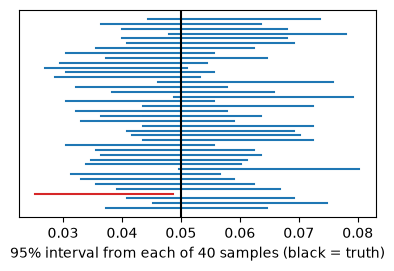

In [2]:
def interval_coverage():
    rng = np.random.default_rng(0)
    true_p, n, trials = 0.05, 1000, 2000
    wins = rng.binomial(n, true_p, trials) / n
    half = 1.96 * np.sqrt(wins * (1 - wins) / n)
    covered = (wins - half <= true_p) & (true_p <= wins + half)
    print("intervals containing the truth:", round(float(covered.mean()), 3))
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    for i in range(40):
        ax.plot([wins[i] - half[i], wins[i] + half[i]], [i, i], color="tab:blue" if covered[i] else "tab:red")
    ax.axvline(true_p, color="black")
    ax.set_xlabel("95% interval from each of 40 samples (black = truth)")
    ax.set_yticks([])


interval_coverage()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q3](#q3), [Q9](#q9). Try one now, or carry on and do them in Part 3.

## Lesson 2: The A/B test, end to end

*Level: Core*

Control: 200 of 2,000 convert (10%). Treatment: 250 of 2,000 (12.5%). Is it real?



1. **Null hypothesis:** no real difference.
2. **Pooled rate,** since under the null there's one rate: 450 / 4000 = 0.1125.
3. **Standard error:** √(0.1125 × 0.8875 × (1/2000 + 1/2000)) = 0.00999.
4. **z:** (0.125 − 0.10) / 0.00999 = **2.502**.
5. **p-value:** two-sided, **0.0124**.



**What the p-value means:** if there were truly no difference, a gap at least this large would appear about 1.2% of the time. It is **not** the probability that the treatment doesn't work, and it says nothing about how big or valuable the effect is.



With 10 vs 11 out of 100, the same maths gives z = 0.23 and p = 0.82: no evidence, though that's not proof of no effect.



|   | Actually no effect | Actually an effect |
| --- | --- | --- |
| Say "effect" | Type I error (rate α, often 5%) | Correct (rate = power, often 80%) |
| Say "no effect" | Correct | Type II error (rate β) |



**Comparing means** uses a t-test. Welch's version doesn't assume equal variance. **Counts in categories** use chi-square: for [[20, 30], [30, 20]], every expected count is 25, so χ² = 4 × 25/25 = 4.0.

**✏️ Your turn:** you now have what you need for [Q10](#q10), [Q12](#q12), [Q13](#q13). Try one now, or carry on and do them in Part 3.

## Lesson 3: Designing an experiment: sample size and traps

*Level: Core*

**Decide the sample size before you start:**



**n per group ≈ 2 (z\_α + z\_β)² p(1 − p) / δ²**



With a 10% base rate, 95% confidence and 80% power (1.96 + 0.84 = 2.8):



| Smallest effect δ | Calculation | Per group |
| --- | --- | --- |
| 2 points | 2 × 7.84 × 0.09 / 0.0004 | 3,528 |
| 1 point | 2 × 7.84 × 0.09 / 0.0001 | 14,112 |



Half the effect needs four times the traffic.



**Trap 1: peeking.** Checking repeatedly and stopping as soon as p &lt; 0.05 inflates false positives a lot, because you get many chances to be fooled. The demo simulates A/A tests, which have no real effect at all. In this run, a single look at the end gives a 5.7% false-positive rate, close to the promised 5%, while stopping at the first significant peek out of 20 gives **25.7%**. Either fix the duration up front, or use a sequential method built for this.



**Trap 2: many comparisons.** Test 20 metrics at 5%, and the chance of at least one false alarm is 1 − 0.95²⁰ = **64%**. Name one primary metric in advance, or correct: Bonferroni tests at 0.05 / 20 = 0.0025.



**Trap 3: a broken split.** With a 50/50 design and counts of 5,000 and 5,400, z = −400 / √10400 = −3.92. Chance doesn't do that, so look for a bug. This **sample ratio mismatch** check should come first.



**Other things to mention:**



- **Novelty effects:** run long enough, covering full weeks.
- **Interference:** in a social network or marketplace, groups affect each other, so consider splitting by region or cluster.
- **Guardrail metrics:** latency and unsubscribes must not worsen.
- **Statistical vs practical significance:** with huge samples, tiny and worthless effects become "significant".

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

false positive rate, one look at the end: 0.057
false positive rate, stop at any peek:    0.257


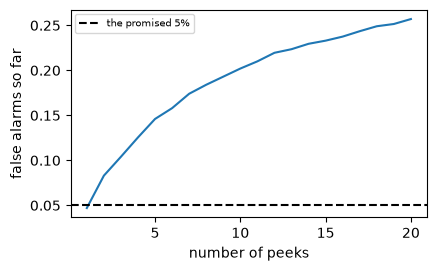

In [3]:
def peeking_inflates():
    rng = np.random.default_rng(1)
    tests, peeks, per_peek = 2000, 20, 100
    p = 0.1
    a = rng.binomial(per_peek, p, (tests, peeks)).cumsum(axis=1)
    b = rng.binomial(per_peek, p, (tests, peeks)).cumsum(axis=1)
    n = per_peek * np.arange(1, peeks + 1)
    pool = (a + b) / (2 * n)
    z = np.abs(a - b) / n / np.sqrt(pool * (1 - pool) * 2 / n)
    print("false positive rate, one look at the end:", round(float((z[:, -1] > 1.96).mean()), 3))
    print("false positive rate, stop at any peek:   ", round(float((z > 1.96).any(axis=1).mean()), 3))
    so_far = (z > 1.96).cumsum(axis=1).astype(bool).mean(axis=0)
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    ax.plot(range(1, peeks + 1), so_far)
    ax.axhline(0.05, color="black", linestyle="--", label="the promised 5%")
    ax.set_xlabel("number of peeks")
    ax.set_ylabel("false alarms so far")
    ax.legend(fontsize=7)


peeking_inflates()

**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q4](#q4), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 4: Probability puzzles: Bayes and base rates

*Level: Core*

A disease affects 1% of people. A test catches 90% of cases, with a 5% false-positive rate. You test positive. What are the chances you're sick? Most people say about 90%.



Imagine 100,000 people:



|   | People | Test positive |
| --- | --- | --- |
| Sick (1%) | 1,000 | 900 |
| Healthy (99%) | 99,000 | 4,950 |



P(sick | positive) = 900 / (900 + 4,950) = **15.4%**. False alarms outnumber real cases because healthy people are so common. It's the same reason a fraud model with high accuracy can still have poor precision.



**Tip:** imagining counts of people is much harder to get wrong than the formula, and it's a good thing to do out loud.



**Expected value.** Pay 4 to play: a 50% chance of 10, otherwise 0. EV = 0.5 × 10 − 4 = **+1**, so it's worth playing, on average.



**Simpson's paradox.** Treatment A beats B in every group, yet loses overall:



| Group | A | B |
| --- | --- | --- |
| Small stones | 81/87 = 93.1% | 234/270 = 86.7% |
| Large stones | 192/263 = 73.0% | 55/80 = 68.8% |
| **Overall** | 273/350 = **78.0%** | 289/350 = **82.6%** |



A gets more of the hard cases, so its overall number is dragged down. Always ask: **what's the mix, and could a hidden variable explain this?**



**Correlation isn't causation.** r runs from −1 to 1 and captures only linear relationships. Ice-cream sales and drownings correlate, because summer drives both. Randomised experiments are how you break that link.



**When there's no neat formula,** as for a median, use the **bootstrap**: resample your data with replacement many times, and look at the spread of the statistic.

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q6](#q6), [Q14](#q14), [Q7](#q7), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 5: Analytics in pandas: the take-home classics

*Level: Advanced*

Many data interviews have a practical round. These patterns come up constantly.



**Funnel.** Count distinct users at each step, and divide by the previous step: visit 4, cart 3 (75%), buy 1 (33.3%). The biggest drop is where to look first. Count users, not events, as one user can trigger many events.



**Cohort retention.** Group users by when they started, then ask what share is still active each week. Cohort 0 has 2 users: both in week 0, one in week 1, one in week 2, so retention is 1.0, 0.5, 0.5.



**Top N per group:**



```python
df.sort_values(["region", "revenue"], ascending=[True, False]).groupby("region").head(n)
```



**Percent of group total.** `transform` returns a result the same shape as the input, unlike `agg`:



```python
df.revenue / df.groupby("region").revenue.transform("sum")
```



**Rolling average.** `s.rolling(3).mean()` smooths noise. For 1, 2, 3, 4, 5 it gives NaN, NaN, 2, 3, 4.



| SQL | pandas |
| --- | --- |
| WHERE | `df[df.x > 1]` |
| GROUP BY … SUM | `df.groupby("g").x.sum()` |
| HAVING | `.filter(lambda g: …)`, or filter after grouping |
| JOIN | `df.merge(other, on="k", how="left")` |
| SUM() OVER (PARTITION BY) | `.transform("sum")` |
| LAG | `.shift()` |
| RANK | `.rank(method="min", ascending=False)` |

**✏️ Your turn:** you now have what you need for [Q17](#q17), [Q20](#q20), [Q18](#q18), [Q19](#q19), [Q8](#q8). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [4]:
import pandas as pd

EVENTS = pd.DataFrame({
    "user": [1, 1, 1, 2, 2, 3, 3, 4],
    "step": ["visit", "cart", "buy", "visit", "cart", "visit", "cart", "visit"],
    "week": [0, 0, 1, 0, 2, 1, 1, 1],
    "cohort": [0, 0, 0, 0, 0, 1, 1, 1],
})

SALES = pd.DataFrame({
    "region": ["N", "N", "N", "S", "S", "E"],
    "product": ["a", "b", "c", "a", "b", "c"],
    "revenue": [50, 30, 20, 40, 60, 10],
})


<a id="q1"></a>
### Q1. Standard Error of a Proportion

🟢 Warm-up · *How noisy is a rate?*

Given conversions and visitors, return (rate, standard error), rounded to 4 decimals.

**Examples**

- `conversions = 50, n = 1000` → `(0.05, 0.0069)`
- `conversions = 500, n = 10000` → `(0.05, 0.0022)`

In [ ]:
def rate_se(conversions, n):
    """
    Given conversions and visitors, return (rate, standard error), rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rate_se, [
    ((50, 1000), (0.05, 0.0069)),
    ((500, 10000), (0.05, 0.0022)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Write the formula step by step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy, one line.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Write the formula step by step.

```python
def rate_se(conversions, n):
    p = conversions / n
    variance = p * (1 - p) / n
    return (round(p, 4), round(math.sqrt(variance), 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** NumPy, one line.

```python
def rate_se(conversions, n):
    p = conversions / n
    return (round(p, 4), round(float(np.sqrt(p * (1 - p) / n)), 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Write the formula step by step. That costs O(1) time and O(1) space."

"I can do better: NumPy, one line. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/standard-error-of-a-proportion)

<a id="q2"></a>
### Q2. 95% Confidence Interval

🟢 Warm-up · *A range, not a point*

Return the 95% interval for a proportion, using 1.96, rounded to 4 decimals.

**Examples**

- `conversions = 50, n = 1000` → `(0.0365, 0.0635)`

In [ ]:
def proportion_ci(conversions, n):
    """
    Return the 95% interval for a proportion, using 1.96, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(proportion_ci, [
    ((50, 1000), (0.0365, 0.0635)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Rate, standard error, then plus or minus.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A NumPy array of ±1.96.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Rate, standard error, then plus or minus.

```python
def proportion_ci(conversions, n):
    p = conversions / n
    se = math.sqrt(p * (1 - p) / n)
    return (round(p - 1.96 * se, 4), round(p + 1.96 * se, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A NumPy array of ±1.96.

```python
def proportion_ci(conversions, n):
    p = conversions / n
    low, high = p + np.array([-1.96, 1.96]) * np.sqrt(p * (1 - p) / n)
    return (round(float(low), 4), round(float(high), 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Rate, standard error, then plus or minus. That costs O(1) time and O(1) space."

"I can do better: A NumPy array of ±1.96. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/95-confidence-interval)

<a id="q3"></a>
### Q3. CI of a Mean

🟢 Warm-up · *Using the sample*

Return (mean, lower, upper) of a 95% interval using the sample standard deviation and 1.96, rounded to 4 decimals. (With few points you'd use t rather than 1.96.)

**Examples**

- `x = [10, 12, 14, 16, 18]` → `(14.0, 11.2281, 16.7719)`

In [ ]:
def mean_ci(x):
    """
    Return (mean, lower, upper) of a 95% interval using the sample standard
    deviation and 1.96, rounded to 4 decimals. (With few points you'd use t
    rather than 1.96.)
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mean_ci, [
    (([10, 12, 14, 16, 18],), (14.0, 11.2281, 16.7719)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute mean and variance with loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.std(x, ddof=1)`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compute mean and variance with loops.

```python
def mean_ci(x):
    n = len(x)
    mean = sum(x) / n
    s = math.sqrt(sum((v - mean) ** 2 for v in x) / (n - 1))
    half = 1.96 * s / math.sqrt(n)
    return (round(mean, 4), round(mean - half, 4), round(mean + half, 4))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.std(x, ddof=1)`.

```python
def mean_ci(x):
    x = np.array(x, dtype=float)
    half = 1.96 * x.std(ddof=1) / np.sqrt(len(x))
    return (round(float(x.mean()), 4), round(float(x.mean() - half), 4), round(float(x.mean() + half), 4))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute mean and variance with loops. That costs O(n) time and O(1) space."

"I can do better: `np.std(x, ddof=1)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/ci-of-a-mean)

<a id="q4"></a>
### Q4. Bonferroni and False Positives

🟢 Warm-up · *Testing many things*

For m independent tests at level a, return (chance of at least one false positive, Bonferroni level a/m), rounded to 4 decimals.

**Examples**

- `m = 20, a = 0.05` → `(0.6415, 0.0025)`
- `m = 1, a = 0.05` → `(0.05, 0.05)`

In [ ]:
def false_positives(m, a):
    """
    For m independent tests at level a, return (chance of at least one false
    positive, Bonferroni level a/m), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(false_positives, [
    ((20, 0.05), (0.6415, 0.0025)),
    ((1, 0.05), (0.05, 0.05)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply the 'no false positive' chance in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A power.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Multiply the 'no false positive' chance in a loop.

```python
def false_positives(m, a):
    none = 1.0
    for _ in range(m):
        none *= 1 - a
    return (round(1 - none, 4), round(a / m, 4))
```

**Cost:** O(m) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A power.

```python
def false_positives(m, a):
    return (round(1 - (1 - a) ** m, 4), round(a / m, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply the 'no false positive' chance in a loop. That costs O(m) time and O(1) space."

"I can do better: A power. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/bonferroni-and-false-positives)

<a id="q5"></a>
### Q5. Bayes: The Rare-Disease Test

🟢 Warm-up · *Base rates*

Given prevalence, sensitivity and false-positive rate, return P(disease | positive), rounded to 4 decimals.

**Examples**

- `prev = 0.01, sens = 0.9, fpr = 0.05` → `0.1538`
- `prev = 0.5, sens = 0.9, fpr = 0.05` → `0.9474`

In [ ]:
def disease_given_positive(prev, sens, fpr):
    """
    Given prevalence, sensitivity and false-positive rate, return P(disease |
    positive), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(disease_given_positive, [
    ((0.01, 0.9, 0.05), 0.1538),
    ((0.5, 0.9, 0.05), 0.9474),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count imaginary people out of 100,000.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Bayes' rule directly.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Count imaginary people out of 100,000.

```python
def disease_given_positive(prev, sens, fpr):
    people = 100000
    sick = people * prev
    true_pos = sick * sens
    false_pos = (people - sick) * fpr
    return round(true_pos / (true_pos + false_pos), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Bayes' rule directly.

```python
def disease_given_positive(prev, sens, fpr):
    return round(prev * sens / (prev * sens + (1 - prev) * fpr), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count imaginary people out of 100,000. That costs O(1) time and O(1) space."

"I can do better: Bayes' rule directly. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/bayes-the-rare-disease-test)

<a id="q6"></a>
### Q6. Expected Value of a Bet

🟢 Warm-up · *Should you play?*

Given (probability, payoff) outcomes and a cost to play, return the expected profit, rounded to 4 decimals.

**Examples**

- `outcomes = [(0.5, 10), (0.5, 0)], cost = 4` → `1.0`
- `outcomes = [(0.16666666666666666, 6), (0.16666666666666666, 6), (0.16666666666666666, 6), (0.16666666666666666, 6), (0.16666666666666666, 6), (0.16666666666666666, 6)], cost = 3.5` → `2.5`

In [ ]:
def expected_profit(outcomes, cost):
    """
    Given (probability, payoff) outcomes and a cost to play, return the expected
    profit, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(expected_profit, [
    (([(0.5, 10), (0.5, 0)], 4), 1.0),
    (([(0.16666666666666666, 6), (0.16666666666666666, 6), (0.16666666666666666, 6), (0.16666666666666666, 6), (0.16666666666666666, 6), (0.16666666666666666, 6)], 3.5), 2.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add up in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dot product.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Add up in a loop.

```python
def expected_profit(outcomes, cost):
    total = 0.0
    for p, pay in outcomes:
        total += p * pay
    return round(total - cost, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dot product.

```python
def expected_profit(outcomes, cost):
    o = np.array(outcomes)
    return round(float(o[:, 0] @ o[:, 1] - cost), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add up in a loop. That costs O(n) time and O(1) space."

"I can do better: A dot product. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/expected-value-of-a-bet)

<a id="q7"></a>
### Q7. Correlation by Hand

🟢 Warm-up · *Pearson's r*

Return Pearson's correlation, rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 4], y = [2, 4, 6, 8]` → `1.0`
- `x = [1, 2, 3, 4], y = [4, 1, 3, 2]` → `-0.4`

In [ ]:
def pearson(x, y):
    """
    Return Pearson's correlation, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pearson, [
    (([1, 2, 3, 4], [2, 4, 6, 8]), 1.0),
    (([1, 2, 3, 4], [4, 1, 3, 2]), -0.4),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Covariance over the two standard deviations.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.corrcoef`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Covariance over the two standard deviations.

```python
def pearson(x, y):
    mx, my = sum(x) / len(x), sum(y) / len(y)
    cov = sum((a - mx) * (b - my) for a, b in zip(x, y))
    sx = math.sqrt(sum((a - mx) ** 2 for a in x))
    sy = math.sqrt(sum((b - my) ** 2 for b in y))
    return round(cov / (sx * sy), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.corrcoef`.

```python
def pearson(x, y):
    return round(float(np.corrcoef(x, y)[0, 1]), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Covariance over the two standard deviations. That costs O(n) time and O(1) space."

"I can do better: `np.corrcoef`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/correlation-by-hand)

<a id="q8"></a>
### Q8. Rolling Average

🟢 Warm-up · *Smoothing a metric*

Return the k-period rolling mean, with None for the first k−1 positions, rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5], k = 3` → `[None, None, 2.0, 3.0, 4.0]`

In [ ]:
def rolling_mean(x, k):
    """
    Return the k-period rolling mean, with None for the first k−1 positions,
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rolling_mean, [
    (([1, 2, 3, 4, 5], 3), [None, None, 2.0, 3.0, 4.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Average each slice.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Series.rolling(k).mean()`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Average each slice.

```python
def rolling_mean(x, k):
    return [None if i + 1 < k else round(sum(x[i + 1 - k:i + 1]) / k, 4) for i in range(len(x))]
```

**Cost:** O(n·k) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `Series.rolling(k).mean()`.

```python
def rolling_mean(x, k):
    s = pd.Series(x, dtype=float).rolling(k).mean().round(4)
    return [None if pd.isna(v) else float(v) for v in s]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Average each slice. That costs O(n·k) time and O(n) space."

"I can do better: `Series.rolling(k).mean()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/rolling-average)

<a id="q9"></a>
### Q9. Margin of Error vs Sample Size

🟢 Warm-up · *Quadruple the data, halve the error*

Return the 95% margin of error (1.96·SE) of a proportion p for each sample size, rounded to 4 decimals.

**Examples**

- `p = 0.5, sizes = [100, 400, 1600]` → `[0.098, 0.049, 0.0245]`

In [ ]:
def margins(p, sizes):
    """
    Return the 95% margin of error (1.96·SE) of a proportion p for each sample
    size, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(margins, [
    ((0.5, [100, 400, 1600]), [0.098, 0.049, 0.0245]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over sizes.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised with NumPy.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loop over sizes.

```python
def margins(p, sizes):
    return [round(1.96 * math.sqrt(p * (1 - p) / n), 4) for n in sizes]
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Vectorised with NumPy.

```python
def margins(p, sizes):
    return (1.96 * np.sqrt(p * (1 - p) / np.array(sizes))).round(4)
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over sizes. That costs O(k) time and O(k) space."

"I can do better: Vectorised with NumPy. That's O(k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/margin-of-error-vs-sample-size)

<a id="q10"></a>
### Q10. Two-Proportion z-Test

🟡 Interview standard · *The A/B test*

Return (z, two-sided p-value), rounded to 4 decimals, using the pooled rate.

**Examples**

- `x1 = 200, n1 = 2000, x2 = 250, n2 = 2000` → `(2.502, 0.0124)`
- `x1 = 10, n1 = 100, x2 = 11, n2 = 100` → `(0.2307, 0.8176)`

In [ ]:
def ab_test(x1, n1, x2, n2):
    """
    Return (z, two-sided p-value), rounded to 4 decimals, using the pooled rate.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ab_test, [
    ((200, 2000, 250, 2000), (2.502, 0.0124)),
    ((10, 100, 11, 100), (0.2307, 0.8176)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Pool, standard error, z, and the normal CDF, step by step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Compact with `math.erf`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Pool, standard error, z, and the normal CDF, step by step.

```python
def ab_test(x1, n1, x2, n2):
    p1, p2 = x1 / n1, x2 / n2
    pool = (x1 + x2) / (n1 + n2)
    se = math.sqrt(pool * (1 - pool) * (1 / n1 + 1 / n2))
    z = (p2 - p1) / se
    cdf = 0.5 * (1 + math.erf(abs(z) / math.sqrt(2)))
    return (round(z, 4), round(2 * (1 - cdf), 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Compact with `math.erf`.

```python
def ab_test(x1, n1, x2, n2):
    pool = (x1 + x2) / (n1 + n2)
    z = (x2 / n2 - x1 / n1) / math.sqrt(pool * (1 - pool) * (1 / n1 + 1 / n2))
    return (round(z, 4), round(math.erfc(abs(z) / math.sqrt(2)), 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Pool, standard error, z, and the normal CDF, step by step. That costs O(1) time and O(1) space."

"I can do better: Compact with `math.erf`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/two-proportion-z-test)

<a id="q11"></a>
### Q11. Sample Size for an A/B Test

🟡 Interview standard · *Before you run it*

Return visitors per group, rounded up: 2·(1.96 + 0.84)²·p(1−p)/δ², for base rate p and smallest difference δ worth detecting.

**Examples**

- `p = 0.1, delta = 0.01` → `14112`
- `p = 0.1, delta = 0.02` → `3528`

In [ ]:
def sample_size(p, delta):
    """
    Return visitors per group, rounded up: 2·(1.96 + 0.84)²·p(1−p)/δ², for base
    rate p and smallest difference δ worth detecting.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sample_size, [
    ((0.1, 0.01), 14112),
    ((0.1, 0.02), 3528),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Step by step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One line.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Step by step.

```python
def sample_size(p, delta):
    z_total = 1.96 + 0.84
    numerator = 2 * z_total * z_total * p * (1 - p)
    return math.ceil(numerator / (delta * delta))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One line.

```python
def sample_size(p, delta):
    return math.ceil(2 * 2.8 ** 2 * p * (1 - p) / delta ** 2)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Step by step. That costs O(1) time and O(1) space."

"I can do better: One line. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/sample-size-for-an-a-b-test)

<a id="q12"></a>
### Q12. Welch's t Statistic

🟡 Interview standard · *Comparing two means*

Return (a̅ − b̅) / √(s²a/na + s²b/nb), with sample variances, rounded to 4 decimals.

**Examples**

- `a = [12, 14, 16, 18], b = [10, 11, 12, 13]` → `2.4249`

In [ ]:
def welch_t(a, b):
    """
    Return (a̅ − b̅) / √(s²a/na + s²b/nb), with sample variances, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(welch_t, [
    (([12, 14, 16, 18], [10, 11, 12, 13]), 2.4249),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Means and variances by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy with `ddof=1`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Means and variances by hand.

```python
def welch_t(a, b):
    def stats(x):
        m = sum(x) / len(x)
        return m, sum((v - m) ** 2 for v in x) / (len(x) - 1)
    ma, va = stats(a)
    mb, vb = stats(b)
    return round((ma - mb) / math.sqrt(va / len(a) + vb / len(b)), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** NumPy with `ddof=1`.

```python
def welch_t(a, b):
    a, b = np.array(a, float), np.array(b, float)
    return round(float((a.mean() - b.mean()) / np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Means and variances by hand. That costs O(n) time and O(1) space."

"I can do better: NumPy with `ddof=1`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/welchs-t-statistic)

<a id="q13"></a>
### Q13. Chi-Square for a 2×2 Table

🟡 Interview standard · *Independent?*

Return Σ(observed − expected)²/expected, rounded to 4 decimals.

**Examples**

- `table = [[20, 30], [30, 20]]` → `4.0`

In [ ]:
def chi_square(table):
    """
    Return Σ(observed − expected)²/expected, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(chi_square, [
    (([[20, 30], [30, 20]],), 4.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Row and column totals, with loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.outer(rows, cols) / total`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Row and column totals, with loops.

```python
def chi_square(table):
    rows = [sum(r) for r in table]
    cols = [sum(r[j] for r in table) for j in range(len(table[0]))]
    total = sum(rows)
    stat = 0.0
    for i, r in enumerate(table):
        for j, obs in enumerate(r):
            exp = rows[i] * cols[j] / total
            stat += (obs - exp) ** 2 / exp
    return round(stat, 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.outer(rows, cols) / total`.

```python
def chi_square(table):
    t = np.array(table, float)
    exp = np.outer(t.sum(axis=1), t.sum(axis=0)) / t.sum()
    return round(float(((t - exp) ** 2 / exp).sum()), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Row and column totals, with loops. That costs O(1) time and O(1) space."

"I can do better: `np.outer(rows, cols) / total`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/chi-square-for-a-2-2-table)

<a id="q14"></a>
### Q14. Simpson's Paradox

🟡 Interview standard · *Aggregates can flip*

Each group is (A wins, A trials, B wins, B trials). Return (groups where A's rate beats B's, overall A rate, overall B rate), rounded to 4 decimals.

**Examples**

- `groups = [(81, 87, 234, 270), (192, 263, 55, 80)]` → `(2, 0.78, 0.8257)`

In [ ]:
def simpson(groups):
    """
    Each group is (A wins, A trials, B wins, B trials). Return (groups where A's
    rate beats B's, overall A rate, overall B rate), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(simpson, [
    (([(81, 87, 234, 270), (192, 263, 55, 80)],), (2, 0.78, 0.8257)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop with running totals.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Array columns.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loop with running totals.

```python
def simpson(groups):
    wins = 0
    aw = at = bw = bt = 0
    for a, n, b, m in groups:
        if a / n > b / m:
            wins += 1
        aw += a
        at += n
        bw += b
        bt += m
    return (wins, round(aw / at, 4), round(bw / bt, 4))
```

**Cost:** O(g) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Array columns.

```python
def simpson(groups):
    g = np.array(groups, float)
    return (int((g[:, 0] / g[:, 1] > g[:, 2] / g[:, 3]).sum()),
            round(float(g[:, 0].sum() / g[:, 1].sum()), 4), round(float(g[:, 2].sum() / g[:, 3].sum()), 4))
```

**Cost:** O(g) time, O(g) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop with running totals. That costs O(g) time and O(1) space."

"I can do better: Array columns. That's O(g) time and O(g) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/simpsons-paradox)

<a id="q15"></a>
### Q15. Bootstrap a Median

🟡 Interview standard · *When there's no neat formula*

Given explicit resamples of row indices, return the median of the data in each, sorted. (Real code would draw thousands at random.)

**Examples**

- `x = [1, 2, 3, 100], resamples = [[0, 1, 2, 3], [3, 3, 2, 1], [0, 0, 1, 1]]` → `[1.5, 2.5, 51.5]`

In [ ]:
def bootstrap_medians(x, resamples):
    """
    Given explicit resamples of row indices, return the median of the data in
    each, sorted. (Real code would draw thousands at random.)
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bootstrap_medians, [
    (([1, 2, 3, 100], [[0, 1, 2, 3], [3, 3, 2, 1], [0, 0, 1, 1]]), [1.5, 2.5, 51.5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort each resample and pick the middle.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.median(x[idx], axis=1)`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Sort each resample and pick the middle.

```python
def bootstrap_medians(x, resamples):
    out = []
    for rows in resamples:
        s = sorted(x[i] for i in rows)
        m = len(s) // 2
        out.append((s[m - 1] + s[m]) / 2 if len(s) % 2 == 0 else s[m])
    return sorted(out)
```

**Cost:** O(r·n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.median(x[idx], axis=1)`.

```python
def bootstrap_medians(x, resamples):
    return np.sort(np.median(np.array(x)[np.array(resamples)], axis=1))
```

**Cost:** O(r·n) time, O(r·n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort each resample and pick the middle. That costs O(r·n log n) time and O(n) space."

"I can do better: `np.median(x[idx], axis=1)`. That's O(r·n) time and O(r·n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/bootstrap-a-median)

<a id="q16"></a>
### Q16. Sample Ratio Mismatch

🟡 Interview standard · *Is the split broken?*

With an intended 50/50 split, return (z, whether |z| &gt; 3). A real experiment failing this check shouldn't be trusted.

**Examples**

- `a = 5000, b = 5100` → `(-0.995, False)`
- `a = 5000, b = 5400` → `(-3.9223, True)`

In [ ]:
def sample_ratio(a, b):
    """
    With an intended 50/50 split, return (z, whether |z| > 3). A real experiment
    failing this check shouldn't be trusted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sample_ratio, [
    ((5000, 5100), (-0.995, False)),
    ((5000, 5400), (-3.9223, True)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute the expected count and standard deviation.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One formula.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compute the expected count and standard deviation.

```python
def sample_ratio(a, b):
    n = a + b
    expected = n / 2
    sd = math.sqrt(n * 0.5 * 0.5)
    z = (a - expected) / sd
    return (round(z, 4), abs(z) > 3)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One formula.

```python
def sample_ratio(a, b):
    z = (a - b) / math.sqrt(a + b)
    return (round(z, 4), bool(abs(z) > 3))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute the expected count and standard deviation. That costs O(1) time and O(1) space."

"I can do better: One formula. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/sample-ratio-mismatch)

<a id="q17"></a>
### Q17. Funnel Conversion

🟡 Interview standard · *pandas*

From EVENTS, return distinct users at each of visit, cart, buy, and the share of the previous step, rounded to 4 decimals (first share 1.0).

**Examples**

- `steps = ['visit', 'cart', 'buy']` → `[['visit', 4, 1.0], ['cart', 3, 0.75], ['buy', 1, 0.3333]]`

In [ ]:
def funnel(steps):
    """
    From EVENTS, return distinct users at each of visit, cart, buy, and the
    share of the previous step, rounded to 4 decimals (first share 1.0).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(funnel, [
    ((['visit', 'cart', 'buy'],), [['visit', 4, 1.0], ['cart', 3, 0.75], ['buy', 1, 0.3333]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A set per step in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`groupby('step').user.nunique()`, then `pct_change`-style division.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A set per step in a loop.

```python
def funnel(steps):
    out, prev = [], None
    for s in steps:
        n = len(set(EVENTS[EVENTS.step == s].user))
        out.append([s, n, 1.0 if prev is None else round(n / prev, 4)])
        prev = n
    return out
```

**Cost:** O(n·s) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `groupby('step').user.nunique()`, then `pct_change`-style division.

```python
def funnel(steps):
    counts = EVENTS.groupby("step").user.nunique().reindex(steps)
    share = (counts / counts.shift()).fillna(1.0).round(4)
    return [[s, int(counts[s]), float(share[s])] for s in steps]
```

**Cost:** O(n) time, O(s) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A set per step in a loop. That costs O(n·s) time and O(n) space."

"I can do better: `groupby('step').user.nunique()`, then `pct_change`-style division. That's O(n) time and O(s) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/funnel-conversion)

<a id="q18"></a>
### Q18. Top N per Group in pandas

🟡 Interview standard · *SQL's RANK, in pandas*

From SALES, return the [region, product] with the top n revenues in each region, ordered by region, then by revenue descending.

**Examples**

- `n = 1` → `[['E', 'c'], ['N', 'a'], ['S', 'b']]`
- `n = 2` → `[['E', 'c'], ['N', 'a'], ['N', 'b'], ['S', 'b'], ['S', 'a']]`

In [ ]:
def top_n(n):
    """
    From SALES, return the [region, product] with the top n revenues in each
    region, ordered by region, then by revenue descending.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(top_n, [
    ((1,), [['E', 'c'], ['N', 'a'], ['S', 'b']]),
    ((2,), [['E', 'c'], ['N', 'a'], ['N', 'b'], ['S', 'b'], ['S', 'a']]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over regions and sort each.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sort_values` then `groupby().head(n)`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loop over regions and sort each.

```python
def top_n(n):
    out = []
    for region in sorted(SALES.region.unique()):
        rows = SALES[SALES.region == region].sort_values("revenue", ascending=False)
        out += [[region, p] for p in rows["product"].head(n)]
    return out
```

**Cost:** O(r·n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `sort_values` then `groupby().head(n)`.

```python
def top_n(n):
    top = SALES.sort_values(["region", "revenue"], ascending=[True, False]).groupby("region").head(n)
    return top[["region", "product"]].values.tolist()
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over regions and sort each. That costs O(r·n log n) time and O(n) space."

"I can do better: `sort_values` then `groupby().head(n)`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/top-n-per-group-in-pandas)

<a id="q19"></a>
### Q19. Percent of Group Total

🟡 Interview standard · *transform*

From SALES, return each row's revenue as a percentage of its region's total, rounded to 1 decimal, in the original row order.

**Examples**

- `` → `[50.0, 30.0, 20.0, 40.0, 60.0, 100.0]`

In [ ]:
def percent_of_region():
    """
    From SALES, return each row's revenue as a percentage of its region's total,
    rounded to 1 decimal, in the original row order.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(percent_of_region, [
    ((), [50.0, 30.0, 20.0, 40.0, 60.0, 100.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute a dictionary of totals, then divide.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`groupby().transform('sum')` keeps the shape.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compute a dictionary of totals, then divide.

```python
def percent_of_region():
    totals = {}
    for r, v in zip(SALES.region, SALES.revenue):
        totals[r] = totals.get(r, 0) + v
    return [round(100 * v / totals[r], 1) for r, v in zip(SALES.region, SALES.revenue)]
```

**Cost:** O(n) time, O(r) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `groupby().transform('sum')` keeps the shape.

```python
def percent_of_region():
    return (100 * SALES.revenue / SALES.groupby("region").revenue.transform("sum")).round(1).tolist()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute a dictionary of totals, then divide. That costs O(n) time and O(r) space."

"I can do better: `groupby().transform('sum')` keeps the shape. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/percent-of-group-total)

<a id="q20"></a>
### Q20. Cohort Retention

🔴 Stretch · *A real analytics task*

For cohort c from EVENTS, return the share of its users active in each week 0 to last\_week, rounded to 4 decimals.

**Examples**

- `c = 0, last_week = 2` → `[1.0, 0.5, 0.5]`

In [ ]:
def retention(c, last_week):
    """
    For cohort c from EVENTS, return the share of its users active in each week
    0 to last_week, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(retention, [
    ((0, 2), [1.0, 0.5, 0.5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Set of cohort users, then a set per week.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`groupby('week').user.nunique()`, then `reindex`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Set of cohort users, then a set per week.

```python
def retention(c, last_week):
    rows = EVENTS[EVENTS.cohort == c]
    total = len(set(rows.user))
    return [round(len(set(rows[rows.week == w].user)) / total, 4) for w in range(last_week + 1)]
```

**Cost:** O(n·w) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `groupby('week').user.nunique()`, then `reindex`.

```python
def retention(c, last_week):
    rows = EVENTS[EVENTS.cohort == c]
    weekly = rows.groupby("week").user.nunique().reindex(range(last_week + 1), fill_value=0)
    return (weekly / rows.user.nunique()).round(4).tolist()
```

**Cost:** O(n) time, O(w) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Set of cohort users, then a set per week. That costs O(n·w) time and O(n) space."

"I can do better: `groupby('week').user.nunique()`, then `reindex`. That's O(n) time and O(w) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/interview/#/q/stats-ab/cohort-retention)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What is a p-value?</b></summary>

The probability of data at least this extreme if the null hypothesis were true. It isn't the probability that the null is true, or a measure of effect size.

</details>

<details>
<summary><b>2. Type I vs Type II error?</b></summary>

Type I is a false alarm, claiming an effect that isn't there. Type II is a miss, failing to detect a real effect.

</details>

<details>
<summary><b>3. What is statistical power?</b></summary>

The chance of detecting a real effect of a given size. It grows with sample size and effect size, and is usually targeted at 80%.

</details>

<details>
<summary><b>4. What does a 95% confidence interval mean?</b></summary>

The procedure captures the true value in about 95% of repeated samples. It doesn't mean a 95% probability for this particular interval, in the frequentist view.

</details>

<details>
<summary><b>5. Central limit theorem?</b></summary>

The average of many independent samples is approximately normal, whatever the original distribution (with finite variance). That's why z-tests work on conversion rates.

</details>

<details>
<summary><b>6. Why does peeking at an A/B test cause problems?</b></summary>

Each look is another chance for a false positive, so stopping at the first significant result inflates the error rate. Fix the duration, or use sequential testing.

</details>

<details>
<summary><b>7. Your test shows significance but a tiny effect. Launch?</b></summary>

Not automatically. Compare the confidence interval with the cost of launching and maintaining it, and check guardrail metrics. Statistical significance isn't practical significance.

</details>

<details>
<summary><b>8. A metric dropped 10% this week. How do you investigate?</b></summary>

Check data pipelines first. Then segment by platform, region, new vs returning, and date. Look for releases and seasonality. Then ask whether the numerator or denominator changed.

</details>

<details>
<summary><b>9. Mean vs median?</b></summary>

The mean uses every value and is pulled by outliers. The median is robust. For skewed data like income or latency, prefer the median or percentiles.

</details>

<details>
<summary><b>10. Correlation vs causation?</b></summary>

Correlation is a pattern, which may be due to a hidden common cause or reverse causation. Randomised experiments establish causation.

</details>

<details>
<summary><b>11. What is Simpson's paradox?</b></summary>

A trend in every subgroup reverses in the aggregate, because group sizes differ. Check the mix before trusting an overall number.

</details>

<details>
<summary><b>12. What is selection bias?</b></summary>

The sample differs systematically from the population. A survey answered only by engaged users overstates satisfaction, for example.

</details>

<details>
<summary><b>13. Can't run an experiment. What then?</b></summary>

Use observational methods: difference-in-differences, matching or regression discontinuity. State their assumptions clearly, since they give weaker evidence.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Uncertainty: standard error and confidence intervals
- [ ] I can explain: The A/B test, end to end
- [ ] I can explain: Designing an experiment: sample size and traps
- [ ] I can explain: Probability puzzles: Bayes and base rates
- [ ] I can explain: Analytics in pandas: the take-home classics

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Sample Ratio Mismatch
- [ ] [Q17](#q17) Funnel Conversion
- [ ] [Q18](#q18) Top N per Group in pandas
- [ ] [Q19](#q19) Percent of Group Total
- [ ] [Q20](#q20) Cohort Retention

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.